# Módulo 03

### Notebook 1: Preparando House Prices con criterio de negocio

En el módulo 02 encontramos **19 columnas con nulos**. Hoy decidimos qué hacer con **cada una**, leyendo el diccionario de datos y no "porque sí".

**Al final de este notebook** tendremos `data/processed/house_prices_limpio.csv`, que usaremos en el EDA (notebook 2 de este módulo) y en el modelado (módulos 04 y 05).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from intro_analitica import config
from intro_analitica.datos import cargar_house_prices

sns.set_theme(style="whitegrid")
df = cargar_house_prices()
print(df.shape)

def nulos(df: pd.DataFrame) -> pd.Series:
    """Columnas con nulos, de más a menos."""
    conteo = df.isna().sum()
    return conteo[conteo > 0].sort_values(ascending=False)

nulos(df)

(1460, 81)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64

## La pregunta clave: ¿por qué falta el dato?

```
                 ¿Por qué falta?
                       │
      ┌────────────────┼──────────────────┐
  "No existe"     "No se registró"     "Es inconsistente"
 (no tiene piscina) (error de captura)  (tiene sótano pero sin datos)
      │                │                   │
 Codificar como     Imputar             Eliminar la fila
 "No Pool" / 0      (mediana, moda…)    (si son pocas)
```

---
## Paso 1: categóricas donde NaN = "no tiene"

El diccionario lo dice explícitamente. Por ejemplo, `PoolQC: NA = No Pool`. Comprobémoslo con los datos:

In [2]:
print("Casas sin dato de PoolQC:", df["PoolQC"].isna().sum())
print("De ellas, ¿cuántas tienen PoolArea = 0?:", (df.loc[df["PoolQC"].isna(), "PoolArea"] == 0).sum())

Casas sin dato de PoolQC: 1453
De ellas, ¿cuántas tienen PoolArea = 0?: 1453


Todas las casas sin `PoolQC` tienen `PoolArea = 0`. **No tienen piscina.** Imputar con la moda (`"Gd"`) sería **inventar piscinas**.

In [3]:
df["Alley"] = df["Alley"].fillna("No Alley")
df["PoolQC"] = df["PoolQC"].fillna("No Pool")
df["Fence"] = df["Fence"].fillna("No Fence")

# MiscFeature: ¿NaN cuando MiscVal = 0?
print("MiscVal de casas sin MiscFeature:", df.loc[df["MiscFeature"].isna(), "MiscVal"].unique())
df["MiscFeature"] = df["MiscFeature"].fillna("None")

# FireplaceQu: ¿NaN cuando Fireplaces = 0?
print("Fireplaces de casas sin FireplaceQu:", df.loc[df["FireplaceQu"].isna(), "Fireplaces"].unique())
df["FireplaceQu"] = df["FireplaceQu"].fillna("No Fireplace")

nulos(df)

MiscVal de casas sin MiscFeature: [0]
Fireplaces de casas sin FireplaceQu: [0]


MasVnrType      872
LotFrontage     259
GarageType       81
GarageYrBlt      81
GarageFinish     81
GarageQual       81
GarageCond       81
BsmtExposure     38
BsmtFinType2     38
BsmtQual         37
BsmtCond         37
BsmtFinType1     37
MasVnrArea        8
Electrical        1
dtype: int64

---
## Paso 2: numéricas "estructurales"

### `LotFrontage` (pies de frente a la calle)

In [4]:
print("Mínimo de LotFrontage:", df["LotFrontage"].min(), "· ¿Hay ceros?", (df["LotFrontage"] == 0).any())

Mínimo de LotFrontage: 21.0 · ¿Hay ceros? False


In [19]:
df["LotFrontage"].isnull().sum()

np.int64(0)

No hay ningún 0, **asumimos** que el `NaN` significa *sin conexión directa a la calle* → 0.

> **Discusión:** otra opción razonable sería imputar con la **mediana del barrio** (casas del mismo barrio tienen frentes parecidos). ¿Cuál preferirías? Lo importante es **documentar la decisión**.

In [5]:
df["LotFrontage"] = df["LotFrontage"].fillna(0)

### Enchape de mampostería (`MasVnrArea`, `MasVnrType`)

In [6]:
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
inconsistentes = df["MasVnrType"].isna() & (df["MasVnrArea"] > 0)
print("Sin tipo de enchape pero con área > 0 (inconsistentes):", inconsistentes.sum())
df.loc[inconsistentes, ["MasVnrType", "MasVnrArea"]]

Sin tipo de enchape pero con área > 0 (inconsistentes): 5


,MasVnrType,MasVnrArea
624,NaN,288.0
773,NaN,1.0
1230,NaN,1.0
1300,NaN,344.0
1334,NaN,312.0


Si el área es 0 → no hay enchape (`"None"`). Si el área es mayor que 0 pero falta el tipo → **inconsistente**: lo dejamos como `NaN` para eliminarlo al final.

In [ ]:
sin_enchape = df["MasVnrArea"] == 0
df.loc[sin_enchape, "MasVnrType"] = df.loc[sin_enchape, "MasVnrType"].fillna("None")
# a las casas con 0 pies² de enchape, si no tienen tipo de enchape, ponles None

---
## Paso 3: familias de columnas (sótano y garaje)

Los nulos de sótano aparecen **juntos** en las mismas casas. La regla: si `TotalBsmtSF == 0`, la casa no tiene sótano.

In [ ]:
columnas_sotano = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
sin_sotano = df["TotalBsmtSF"] == 0
print("Casas sin sótano:", sin_sotano.sum())
for col in columnas_sotano:
    df.loc[sin_sotano, col] = df.loc[sin_sotano, col].fillna("No Basement")

# ¿Quedó algo raro?
df.loc[df[columnas_sotano].isna().any(axis=1), ["TotalBsmtSF"] + columnas_sotano]
# muéstrame las casas a las que les falta al menos un dato del sótano, con su área de sótano y sus cinco columnas de sótano
# axis=1 para que devuelva True si alguna columna es NaN

Casas sin sótano: 37


,TotalBsmtSF,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
332,3206,Gd,TA,No,GLQ,NaN
948,936,Gd,TA,NaN,Unf,Unf


Quedan **2 casas** que **sí** tienen sótano pero les falta `BsmtExposure` o `BsmtFinType2`. Son inconsistentes → se eliminarán.

Con el garaje hacemos lo mismo, usando `GarageArea == 0`. `GarageYrBlt` es numérica: usamos **-1** como **valor centinela**.

> **Un centinela es una señal, no una cantidad.** Si luego calculas "edad del garaje = YrSold − GarageYrBlt", las casas sin garaje darían 2009 años. Hay que tratarlas aparte.

In [9]:
columnas_garaje = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
sin_garaje = df["GarageArea"] == 0
for col in columnas_garaje:
    df.loc[sin_garaje, col] = df.loc[sin_garaje, col].fillna("No Garage")
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(-1).astype(int)

nulos(df)

MasVnrType      5
BsmtExposure    1
BsmtFinType2    1
Electrical      1
dtype: int64

In [22]:
df[df["GarageYrBlt"]==-1] [["GarageArea", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "GarageYrBlt"]]

,GarageArea,GarageType,GarageFinish,GarageQual,GarageCond,GarageYrBlt
39,0,No Garage,No Garage,No Garage,No Garage,-1
48,0,No Garage,No Garage,No Garage,No Garage,-1
78,0,No Garage,No Garage,No Garage,No Garage,-1
88,0,No Garage,No Garage,No Garage,No Garage,-1
89,0,No Garage,No Garage,No Garage,No Garage,-1
...,...,...,...,...,...,...
1342,0,No Garage,No Garage,No Garage,No Garage,-1
1399,0,No Garage,No Garage,No Garage,No Garage,-1
1441,0,No Garage,No Garage,No Garage,No Garage,-1
1442,0,No Garage,No Garage,No Garage,No Garage,-1


---
## Paso 4: eliminar los inconsistentes

In [10]:
df[df.isna().any(axis=1)][nulos(df).index.tolist()]

,MasVnrType,BsmtExposure,BsmtFinType2,Electrical
332,BrkFace,No,NaN,SBrkr
624,NaN,No,Unf,SBrkr
773,NaN,No,Unf,FuseA
948,BrkFace,NaN,Unf,SBrkr
1230,NaN,No,Rec,SBrkr
1300,NaN,No,Unf,SBrkr
1334,NaN,No,Unf,SBrkr
1379,None,No,Unf,NaN


In [11]:
antes = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Eliminadas {antes - len(df)} filas ({(antes - len(df)) / antes:.1%}) · Nulos restantes: {int(df.isna().sum().sum())}")

Eliminadas 8 filas (0.5%) · Nulos restantes: 0


Perder el **0.5 %** de los datos es aceptable y más honesto que inventar valores.

**Lección principal:** un nulo no siempre es un error. Antes de rellenarlo o eliminarlo hay que preguntarse por qué falta, y cuando dos columnas describen lo mismo, usar una para comprobar la otra.

---
## Paso 5: *feature engineering*, variables con sentido de negocio

El comprador no piensa en "año de construcción" sino en **qué tan vieja** está la casa. Creamos variables que hablan el idioma del negocio:

In [ ]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["YearsSinceRemod"] = df["YrSold"] - df["YearRemodAdd"]
df["Remodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
# area total de la casa, considerar sotano y pisos
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
# area total de baños, considerar baños completos y medios baños, sotano y pisos
df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]

df[["HouseAge", "YearsSinceRemod", "Remodeled", "TotalSF", "TotalBath", "SalePrice"]].corr()["SalePrice"].round(2)

HouseAge          -0.52
YearsSinceRemod   -0.51
Remodeled         -0.02
TotalSF            0.78
TotalBath          0.63
SalePrice          1.00
Name: SalePrice, dtype: float64

`TotalSF` (r ≈ 0.78) se correlaciona con el precio **más** que cualquiera de sus partes por separado.

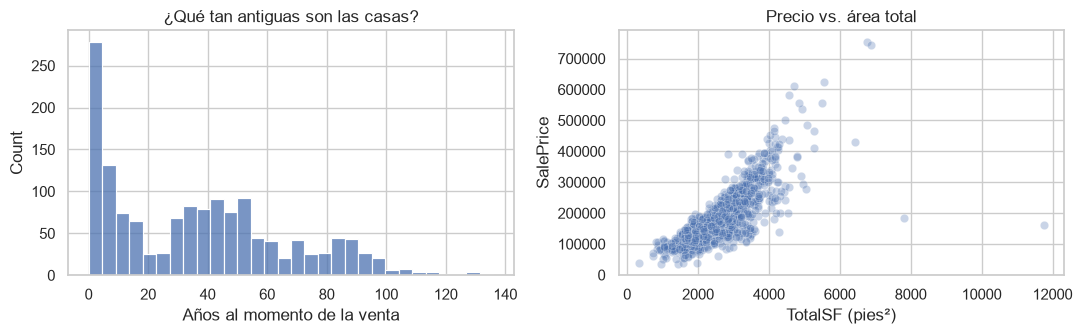

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["HouseAge"], bins=30, ax=axes[0])
axes[0].set(title="¿Qué tan antiguas son las casas?", xlabel="Años al momento de la venta")
sns.scatterplot(data=df, x="TotalSF", y="SalePrice", alpha=0.3, ax=axes[1])
axes[1].set(title="Precio vs. área total", xlabel="TotalSF (pies²)")
plt.tight_layout()
plt.show()

### Discusión

**Antigüedad de las casas (izquierda).** Muchas casas son nuevas: cerca de una de cada cinco tenía 5 años o menos al venderse, lo que muestra que en esos años se construyó mucho en Ames. Después aparece un "valle" entre los 15 y los 30 años, cuando se construyeron pocas casas, y luego un segundo grupo grande de casas de 30 a 60 años. La casa típica tiene 35 años, aunque hay algunas de más de 100. Las casas más nuevas suelen venderse más caras, así que la edad es una variable útil para el modelo.

**Precio frente a área total (derecha).** La relación es clara: a más área total, mayor precio, y los puntos forman una nube bastante ordenada. Esto confirma que `TotalSF`, la variable que creamos, es una de las que más se relacionan con el precio. Hay dos excepciones evidentes abajo a la derecha: dos casas de más de 7.000 pies² vendidas por menos de USD 200.000. No son errores: son casas del barrio Edwards vendidas sin terminar (`SaleCondition = Partial`). **Detectar un valor atípico no significa eliminarlo**: primero hay que entender por qué es diferente y luego decidir, con un argumento, si se deja o se quita.

---
## Paso 6: del notebook al código reutilizable

Todo lo que hicimos celda por celda está empaquetado en `src/intro_analitica/limpieza.py`, con una función por paso.
Comprobemos que **da exactamente el mismo resultado**:

In [14]:
from intro_analitica.limpieza import agregar_variables, limpiar_house_prices

df_funcion = agregar_variables(limpiar_house_prices(cargar_house_prices(), verbose=True))
pd.testing.assert_frame_equal(df, df_funcion)
print("\n[OK] El notebook y la función producen el mismo DataFrame")

rellenar_no_tiene                   filas= 1460  nulos= 1732
limpiar_numericas_estructurales     filas= 1460  nulos=  517
limpiar_sotano                      filas= 1460  nulos=  332
limpiar_garaje                      filas= 1460  nulos=    8
eliminar_inconsistencias            filas= 1452  nulos=    0

[OK] El notebook y la función producen el mismo DataFrame


## Paso 7: guardar

In [15]:
config.asegurar_carpetas()
df.to_csv(config.HOUSE_PRICES_LIMPIO, index=False)
print("", config.HOUSE_PRICES_LIMPIO.relative_to(config.RAIZ), df.shape)

 data/processed/house_prices_limpio.csv (1452, 86)


### ¿Y el escalado y el one-hot?

**Todavía no.** El escalado y la codificación *aprenden* de los datos (media, categorías). Si los aplicamos ahora, sobre los 1452 registros, el test "contamina" el entrenamiento (*data leakage*).
Los haremos **dentro del Pipeline** en el módulo 05, aprendiendo solo del train.

---
## Registro de decisiones (así se documenta en el proyecto)

| Columna(s) | Problema | Decisión | Justificación |
|---|---|---|---|
| `PoolQC`, `Alley`, `Fence`, `MiscFeature`, `FireplaceQu` | >45 % de nulos | Categoría "No …" | Diccionario: NA = no tiene; verificado con `PoolArea`, `Fireplaces` |
| `LotFrontage` | 259 nulos | 0 | No hay ceros, se asume sin frente a la calle (alternativa: mediana del barrio) |
| `MasVnrArea` / `MasVnrType` | 8 / 872 nulos | 0 / "None"; inconsistentes → eliminar | Sin área = sin enchape |
| `Bsmt*` | 37-38 nulos | "No Basement" si `TotalBsmtSF == 0` | Nulos en bloque = casa sin sótano |
| `Garage*` | 81 nulos | "No Garage"; `GarageYrBlt = -1` | Nulos en bloque = sin garaje; -1 es centinela |
| `Electrical` y otros sueltos | 8 filas en total | Eliminar | Inconsistentes, <1 % de los datos |

---
## Ejercicios guiados (20 min)

1. **Alternativa para `LotFrontage`:** imputa con la **mediana del barrio** (`groupby("Neighborhood")["LotFrontage"].transform("median")`). ¿Cambia mucho la distribución frente a imputar con 0? Haz un histograma de ambas.
2. **Nueva variable:** crea `HasPool` (1 si `PoolArea > 0`) y `GarageAge` (años del garaje, **cuidando el centinela -1**).
3. **Ordinales:** `ExterQual`, `KitchenQual` y `BsmtQual` usan la escala `Po < Fa < TA < Gd < Ex`. Conviértelas a números 1-5 con un `map` (¿qué número le das a "No Basement"?).
4. **Reflexión:** ¿por qué conviene eliminar los duplicados **antes** de imputar? (pista: piensa en cómo cambia la mediana)

Soluciones en `ejercicios/soluciones/solucion_01_preparacion.py`.

In [16]:
# Tu código aquí